In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pd.read_csv("airlines.csv")

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways
5,OO,Skywest Airlines Inc.
6,AS,Alaska Airlines Inc.
7,NK,Spirit Air Lines
8,WN,Southwest Airlines Co.
9,DL,Delta Air Lines Inc.


In [3]:
pd.read_csv("airports.csv")

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447
...,...,...,...,...,...,...,...
317,WRG,Wrangell Airport,Wrangell,AK,USA,56.48433,-132.36982
318,WYS,Westerly State Airport,West Yellowstone,MT,USA,44.68840,-111.11764
319,XNA,Northwest Arkansas Regional Airport,Fayetteville/Springdale/Rogers,AR,USA,36.28187,-94.30681
320,YAK,Yakutat Airport,Yakutat,AK,USA,59.50336,-139.66023


In [4]:
df = pd.read_csv("flights.csv")

/var/folders/9r/brmhv86j4v91sk89156k2r6c0000gn/T/ipykernel_24518/1505972477.py:1: DtypeWarning: Columns (0: ORIGIN_AIRPORT, 1: DESTINATION_AIRPORT) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("flights.csv")


In [5]:
df.head(10)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5,2015,1,1,4,DL,806,N3730B,SFO,MSP,25,...,610.0,8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
6,2015,1,1,4,NK,612,N635NK,LAS,MSP,25,...,509.0,-17.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
7,2015,1,1,4,US,2013,N584UW,LAX,CLT,30,...,753.0,-10.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
8,2015,1,1,4,AA,1112,N3LAAA,SFO,DFW,30,...,532.0,-13.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
9,2015,1,1,4,DL,1173,N826DN,LAS,ATL,30,...,656.0,-15.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   YEAR                 5819079 non-null  int64  
 1   MONTH                5819079 non-null  int64  
 2   DAY                  5819079 non-null  int64  
 3   DAY_OF_WEEK          5819079 non-null  int64  
 4   AIRLINE              5819079 non-null  str    
 5   FLIGHT_NUMBER        5819079 non-null  int64  
 6   TAIL_NUMBER          5804358 non-null  str    
 7   ORIGIN_AIRPORT       5819079 non-null  object 
 8   DESTINATION_AIRPORT  5819079 non-null  object 
 9   SCHEDULED_DEPARTURE  5819079 non-null  int64  
 10  DEPARTURE_TIME       5732926 non-null  float64
 11  DEPARTURE_DELAY      5732926 non-null  float64
 12  TAXI_OUT             5730032 non-null  float64
 13  WHEELS_OFF           5730032 non-null  float64
 14  SCHEDULED_TIME       5819073 non-null  float64
 15  ELAPSED_T

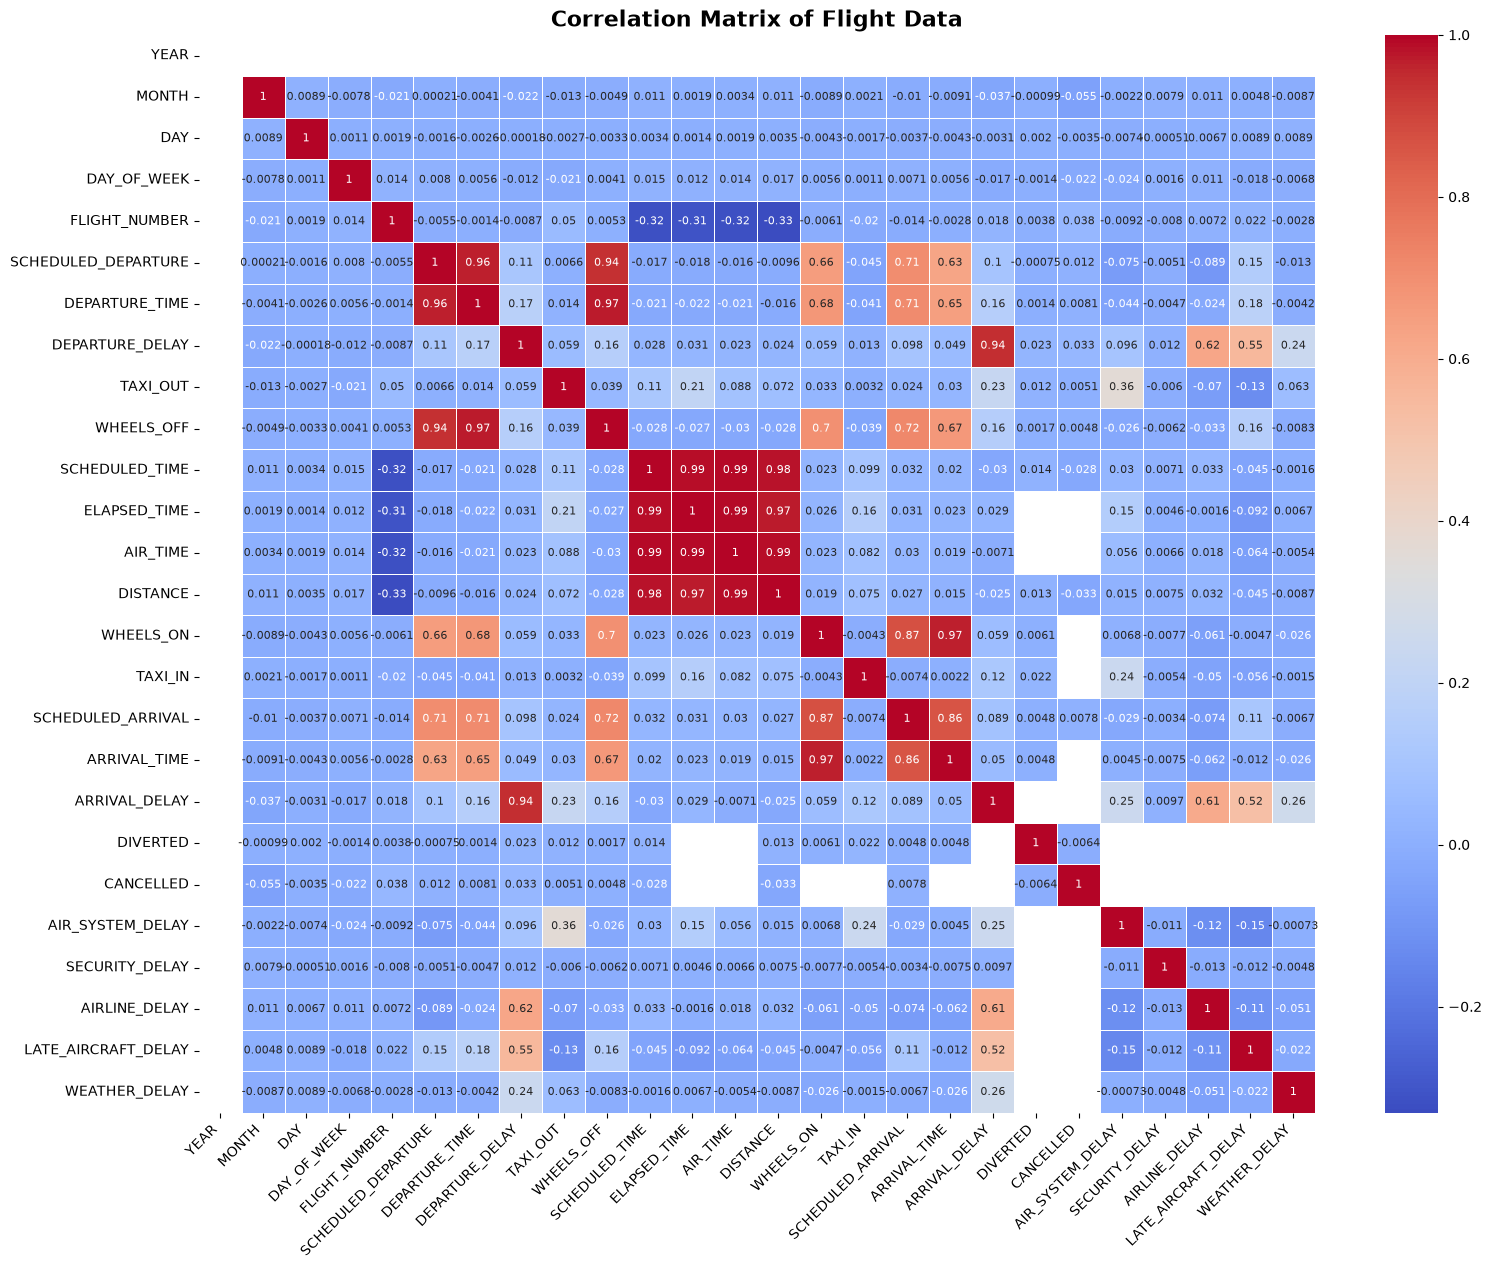

In [7]:
plt.figure(figsize=(18, 14))
corr = df.corr(numeric_only=True)
sns.heatmap(
    corr, 
    cmap='coolwarm',       
    annot=True,                     
    annot_kws={"size": 8}, 
    linewidths=0.5,        
    
)
plt.title("Correlation Matrix of Flight Data", fontsize=16, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

In [8]:
dropcolumns = [
    "YEAR",
    "DIVERTED",
    "CANCELLED",
    "CANCELLATION_REASON",
    "AIR_TIME",
    "ELAPSED_TIME",
    "WHEELS_OFF",
    "WHEELS_ON",
    "TAXI_IN",
    "FLIGHT_NUMBER",
    "TAIL_NUMBER",
    "SCHEDULED_DEPARTURE",
    "ARRIVAL_TIME",
    "AIR_SYSTEM_DELAY",
    "SECURITY_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "WEATHER_DELAY"
]

data = df.drop(columns=dropcolumns).copy()
data = data.dropna(subset=["ARRIVAL_DELAY"])
import gc

del df
gc.collect()

41572

In [9]:
data.head()

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY
0,1,1,4,AS,ANC,SEA,2354.0,-11.0,21.0,205.0,1448,430,-22.0
1,1,1,4,AA,LAX,PBI,2.0,-8.0,12.0,280.0,2330,750,-9.0
2,1,1,4,US,SFO,CLT,18.0,-2.0,16.0,286.0,2296,806,5.0
3,1,1,4,AA,LAX,MIA,15.0,-5.0,15.0,285.0,2342,805,-9.0
4,1,1,4,AS,SEA,ANC,24.0,-1.0,11.0,235.0,1448,320,-21.0


In [10]:
from sklearn.preprocessing import SplineTransformer

time_cols = ["DEPARTURE_TIME", "SCHEDULED_ARRIVAL"]

for col in time_cols:
    data[col + "_MINUTES"] = (
        (data[col] // 100) * 60 + (data[col] % 100)
    ) % 1440

knots = np.linspace(0, 1440, 4).reshape(-1, 1)

for col in time_cols:
    spline = SplineTransformer(
        degree=3,
        knots=knots,
        extrapolation="periodic",
        include_bias=False
    )

    features = spline.fit_transform(
        data[[col + "_MINUTES"]]
    ).astype(np.float32)

    names = [
        f"{col}_SPLINE_{i+1}"
        for i in range(features.shape[1])
    ]

    data[names] = features

data.drop(
    columns=time_cols + [col + "_MINUTES" for col in time_cols],
    inplace=True
)

data.head()
del features
gc.collect()

0

In [11]:
ap=pd.read_csv("airports.csv")

In [12]:
ap.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447


In [13]:
codes = ap["IATA_CODE"].astype("string").str.strip()

ap.loc[codes.str.fullmatch(r"\d+", na=False)]

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE


In [14]:
origin = data["ORIGIN_AIRPORT"].astype("string").str.strip()
destination = data["DESTINATION_AIRPORT"].astype("string").str.strip()

print("Distinct origin identifiers:", origin.nunique())
print("Distinct destination identifiers:", destination.nunique())

print(
    "Distinct identifiers across both:",
    pd.concat([origin, destination]).nunique()
)

Distinct origin identifiers: 628
Distinct destination identifiers: 629
Distinct identifiers across both: 629


In [15]:
for col in ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]:
    data[col] = data[col].astype("string").str.strip()

In [16]:
for col in ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]:
    numeric = data[col].str.fullmatch(r"\d+", na=False)

    print(f"\n{col}: numeric-code flights by month")
    print(pd.crosstab(data["MONTH"], numeric).rename(
        columns={False: "Letter/other codes", True: "Numeric codes"}
    ))

    print("\nExample numeric identifiers:")
    print(data.loc[numeric, col].drop_duplicates().head(10).tolist())


ORIGIN_AIRPORT: numeric-code flights by month
ORIGIN_AIRPORT  Letter/other codes  Numeric codes
MONTH                                            
1                           457013              0
2                           407663              0
3                           492138              0
4                           479251              0
5                           489641              0
6                           492847              0
7                           514384              0
8                           503956              0
9                           462153              0
10                               0         482878
11                          462367              0
12                          469717              0

Example numeric identifiers:
['14747', '14771', '12889', '12892', '14869', '10299', '11292', '14107', '11630', '10732']

DESTINATION_AIRPORT: numeric-code flights by month
DESTINATION_AIRPORT  Letter/other codes  Numeric codes
MONTH                    

In [17]:
aid=pd.read_csv("L_AIRPORT_ID.csv")

In [18]:
a=pd.read_csv("L_AIRPORT.csv")

In [19]:
aid.head()

,Code,Description
0,10001,"Afognak Lake, AK: Afognak Lake Airport"
1,10003,"Granite Mountain, AK: Bear Creek Mining Strip"
2,10004,"Lik, AK: Lik Mining Camp"
3,10005,"Little Squaw, AK: Little Squaw Airport"
4,10006,"Kizhuyak, AK: Kizhuyak Bay"


In [20]:
a.head()

,Code,Description
0,01A,"Afognak Lake, AK: Afognak Lake Airport"
1,03A,"Granite Mountain, AK: Bear Creek Mining Strip"
2,04A,"Lik, AK: Lik Mining Camp"
3,05A,"Little Squaw, AK: Little Squaw Airport"
4,06A,"Kizhuyak, AK: Kizhuyak Bay"


In [21]:
ids = aid.astype("string")
codes = a.astype("string")
airport_cols = ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]

mapping = ids.merge(codes, on="Description", suffixes=("_ID", "_IATA"))

used_ids = pd.concat(
    [data[col].astype("string").str.strip() for col in airport_cols]
).drop_duplicates()

numeric_ids = used_ids[used_ids.str.fullmatch(r"\d+", na=False)]
missing_ids = numeric_ids[~numeric_ids.isin(mapping["Code_ID"])]

matches = mapping.groupby("Code_ID")["Code_IATA"].nunique()
ambiguous_ids = matches[(matches > 1) & matches.index.isin(numeric_ids)].index

print("Unique numeric airport IDs:", len(numeric_ids))

print("\nIDs without an exact description match:")
print(ids.loc[ids["Code"].isin(missing_ids)].to_string(index=False))

print("\nIDs with multiple matching codes:")
print(mapping.loc[
    mapping["Code_ID"].isin(ambiguous_ids)
].to_string(index=False))

unresolved = set(missing_ids) | set(ambiguous_ids)
remove = data[airport_cols].astype("string").isin(unresolved).any(axis=1)

print("\nFlights affected:", remove.sum())
print("Percentage of dataset:", remove.mean() * 100)

Unique numeric airport IDs: 307

IDs without an exact description match:
 Code                                                   Description
10157                                     Arcata/Eureka, CA: Arcata
10408                       Appleton, WI: Outagamie County Regional
10685             Bloomington/Normal, IL: Central Illinois Regional
11066                     Columbus, OH: Port Columbus International
11977                  Green Bay, WI: Austin Straubel International
12173                          Honolulu, HI: Honolulu International
12278                            Wichita, KS: Wichita Mid-Continent
12343                  International Falls, MN: Falls International
12758               Kona, HI: Kona International Airport at Keahole
12951                             Lafayette, LA: Lafayette Regional
13076                            La Crosse, WI: La Crosse Municipal
13158                     Midland/Odessa, TX: Midland International
14193                  Pensacola, FL: Pensa

In [22]:
data = data.loc[~remove].copy()
airport_map = (
    mapping[mapping["Code_ID"].isin(matches[matches == 1].index)]
    .drop_duplicates("Code_ID")
    .set_index("Code_ID")["Code_IATA"]
)


for col in airport_cols:
    values = data[col].astype("string").str.strip()
    mapped = values.map(airport_map)
    data[col] = mapped.fillna(values)


for col in airport_cols:
    numeric = data[col].str.fullmatch(r"\d+", na=False)
    print(col, "rows with unresolved numeric IDs:", numeric.sum())
    print("Missing values:", data[col].isna().sum())

del origin, destination, values, mapped, numeric, remove
gc.collect()

ORIGIN_AIRPORT rows with unresolved numeric IDs: 0
Missing values: 0
DESTINATION_AIRPORT rows with unresolved numeric IDs: 0
Missing values: 0


12

In [23]:
data.info()

<class 'pandas.DataFrame'>
Index: 5672433 entries, 0 to 5819078
Data columns (total 15 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   MONTH                       int64  
 1   DAY                         int64  
 2   DAY_OF_WEEK                 int64  
 3   AIRLINE                     str    
 4   ORIGIN_AIRPORT              string 
 5   DESTINATION_AIRPORT         string 
 6   DEPARTURE_DELAY             float64
 7   TAXI_OUT                    float64
 8   SCHEDULED_TIME              float64
 9   DISTANCE                    int64  
 10  ARRIVAL_DELAY               float64
 11  DEPARTURE_TIME_SPLINE_1     float32
 12  DEPARTURE_TIME_SPLINE_2     float32
 13  SCHEDULED_ARRIVAL_SPLINE_1  float32
 14  SCHEDULED_ARRIVAL_SPLINE_2  float32
dtypes: float32(4), float64(4), int64(4), str(1), string(2)
memory usage: 649.8 MB


In [24]:

for month in range(2, 13):
    data[f"MONTH_{month}"] = (data["MONTH"] == month).astype(np.int8)

for day in range(2, 8):
    data[f"WEEKDAY_{day}"] = (data["DAY_OF_WEEK"] == day).astype(np.int8)

data = data.drop(columns=["MONTH", "DAY_OF_WEEK", "DAY"])

data.head()

,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,DISTANCE,ARRIVAL_DELAY,DEPARTURE_TIME_SPLINE_1,DEPARTURE_TIME_SPLINE_2,...,MONTH_9,MONTH_10,MONTH_11,MONTH_12,WEEKDAY_2,WEEKDAY_3,WEEKDAY_4,WEEKDAY_5,WEEKDAY_6,WEEKDAY_7
0,AS,ANC,SEA,-11.0,21.0,205.0,1448,-22.0,0.172994,0.666511,...,0,0,0,0,0,0,1,0,0,0
1,AA,LAX,PBI,-8.0,12.0,280.0,2330,-9.0,0.164592,0.666649,...,0,0,0,0,0,0,1,0,0,0
2,US,SFO,CLT,-2.0,16.0,286.0,2296,5.0,0.148620,0.665287,...,0,0,0,0,0,0,1,0,0,0
3,AA,LAX,MIA,-5.0,15.0,285.0,2342,-9.0,0.151530,0.665705,...,0,0,0,0,0,0,1,0,0,0
4,AS,SEA,ANC,-1.0,11.0,235.0,1448,-21.0,0.142917,0.664229,...,0,0,0,0,0,0,1,0,0,0


In [25]:
outlier_cols = [
    "DEPARTURE_DELAY", "TAXI_OUT", "SCHEDULED_TIME", "ARRIVAL_DELAY"
]

print(
    data[outlier_cols]
    .describe(percentiles=[0.01, 0.50, 0.95, 0.99, 0.999])
)

       DEPARTURE_DELAY      TAXI_OUT  SCHEDULED_TIME  ARRIVAL_DELAY
count     5.672433e+06  5.672433e+06    5.672433e+06   5.672433e+06
mean      9.332106e+00  1.607990e+01    1.420002e+02   4.444045e+00
std       3.692164e+01  8.892786e+00    7.515814e+01   3.930585e+01
min      -8.200000e+01  1.000000e+00    1.800000e+01  -8.700000e+01
1%       -1.300000e+01  6.000000e+00    4.400000e+01  -3.400000e+01
50%      -2.000000e+00  1.400000e+01    1.230000e+02  -5.000000e+00
95%       6.700000e+01  3.100000e+01    3.080000e+02   6.700000e+01
99%       1.670000e+02  5.000000e+01    3.760000e+02   1.670000e+02
99.9%     3.690000e+02  9.200000e+01    4.600000e+02   3.680000e+02
max       1.988000e+03  2.250000e+02    7.180000e+02   1.971000e+03


In [26]:
data["ROUTE"] = (
    data["ORIGIN_AIRPORT"].astype(str)
    + "_"
    + data["DESTINATION_AIRPORT"].astype(str)
)
data["AIRLINE_ROUTE"] = (
    data["AIRLINE"].astype(str) + "_" + data["ROUTE"].astype(str)
)
data["DEPARTURE_DELAY_X_DISTANCE"] = (
    data["DEPARTURE_DELAY"] * data["DISTANCE"]
)

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import KFold
category_cols = [ "ORIGIN_AIRPORT", "DESTINATION_AIRPORT","ROUTE","AIRLINE_ROUTE"]

X = data.drop(columns="ARRIVAL_DELAY").copy()
y = data["ARRIVAL_DELAY"].copy()

X[category_cols] = X[category_cols].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

encoder = TargetEncoder(
    target_type="continuous",
    smooth="auto",
    cv=KFold(n_splits=5, shuffle=True, random_state=42)
)

X_train[category_cols] = encoder.fit_transform(
    X_train[category_cols], y_train
).astype(np.float32)

X_test[category_cols] = encoder.transform(
    X_test[category_cols]
).astype(np.float32)


del X, y, data
gc.collect()

0

In [28]:
from sklearn.preprocessing import OneHotEncoder

airline_encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.int8
)

train_airlines = airline_encoder.fit_transform(X_train[["AIRLINE"]])
test_airlines = airline_encoder.transform(X_test[["AIRLINE"]])

airline_names = airline_encoder.get_feature_names_out(["AIRLINE"])

X_train = pd.concat([
    X_train.drop(columns="AIRLINE"),
    pd.DataFrame(train_airlines, columns=airline_names, index=X_train.index)
], axis=1)

X_test = pd.concat([
    X_test.drop(columns="AIRLINE"),
    pd.DataFrame(test_airlines, columns=airline_names, index=X_test.index)
], axis=1)

del train_airlines, test_airlines
gc.collect()

0

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)


X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (4537946, 43)
Testing shape: (1134487, 43)


In [ ]:
X = np.column_stack((np.ones(X_train_scaled.shape[0]), X_train_scaled))

y = y_train.to_numpy(dtype=float)

n = X.shape[0]
theta = np.zeros(X.shape[1])

alpha = 0.4
iterations = 500
cost_history = []

for iteration in range(iterations):
    h = X @ theta
    error = h-y

    cost = (error @ error) / (2 * n)
    cost_history.append(cost)


    theta -= (alpha / n) * (X.T @ error)

    if iteration % 10 == 0:
        print(f"Iteration {iteration}: cost = {cost:.4f}")

Iteration 0: cost = 781.2961
Iteration 10: cost = 65.3253
Iteration 20: cost = 54.7000
Iteration 30: cost = 52.1759
Iteration 40: cost = 51.3513
Iteration 50: cost = 50.9215
Iteration 60: cost = 50.6062
Iteration 70: cost = 50.3402
Iteration 80: cost = 50.1062
Iteration 90: cost = 49.8976
Iteration 100: cost = 49.7110
Iteration 110: cost = 49.5439
Iteration 120: cost = 49.3942
Iteration 130: cost = 49.2601
Iteration 140: cost = 49.1400
Iteration 150: cost = 49.0323
Iteration 160: cost = 48.9358
Iteration 170: cost = 48.8493
Iteration 180: cost = 48.7717
Iteration 190: cost = 48.7023
Iteration 200: cost = 48.6400
Iteration 210: cost = 48.5842


In [ ]:

h_test = X_test_scaled @ theta[1:] + theta[0]

y_test_array = y_test.to_numpy(dtype=float)
error = h_test - y_test_array

print(pd.DataFrame({
    "Actual delay": y_test_array[:50],
    "Predicted delay": h_test[:50],
"Diff": h_test[:50] - y_test_array[:50]}).round(2))

In [ ]:
train_predictions = X_train_scaled @ theta[1:] + theta[0]
test_predictions = X_test_scaled @ theta[1:] + theta[0]

for name, actual, predicted in [
    ("Training", y_train.to_numpy(dtype=float), train_predictions),
    ("Testing", y_test.to_numpy(dtype=float), test_predictions)
]:
    errors = predicted - actual

    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(errors))

    r2 = 1 - (
        np.sum(errors ** 2)
        / np.sum((actual - actual.mean()) ** 2)
    )

    print(f"\n{name} results:")
    print(f"MSE:  {mse:.4f}")
    print(f"RMSE: {rmse:.4f} minutes")
    print(f"MAE:  {mae:.4f} minutes")
    print(f"R²:   {r2:.4f}")

    actual = y_test.to_numpy(dtype=float)
residuals = actual - test_predictions

evs = 1 - np.var(residuals) / np.var(actual)
print(f"Explained Variance Score: {evs:.4f}")

In [ ]:
X_train.info()